In [406]:
import numpy as np
import scipy as sc
import pickle as pickle
import os
import matplotlib.pyplot as plt
import import_ipynb
import ipynb.fs.full.ssiProjectModule as ssiMod
import matplotlib as mpl
import math
from tqdm.notebook import tqdm
mpl.rcParams['axes.spines.right']=False
mpl.rcParams['axes.spines.top']=False



print(os.getcwd())

felix_cells = [1,5,8,15]


raw_data_dir = '/home/cparis/00PhD/DS Cells - Franke/Raw Data/'
with open(raw_data_dir+'DS_cells.pkl', 'rb') as rick:
    raw_dict = pickle.load(rick)

/home/cparis/00PhD/DS_PCBreview


In [589]:
print(raw_dict['expBarWidths'])

[[ 500  500  500  500 1000 1000 1000]]


In [426]:
theta_step = 2
main_dir = '/home/cparis/00PhD/'

area_or_max = 'Area'
dat_dir_out = main_dir + f'Simulated Stretch/Analyze stretched quadruplets constrained by AREA or MAX/'

title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'
# title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240506_MAX.pkl'

import pickle5 as pickle5

with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle5.load(rick)
bio_idx = np.where(data_dict['all_multipliers']==1.)[0][0]

In [364]:
print(np.arange(1+np.max(raw_dict['spikeCounts'][:,:,felix_cells])))

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85]
[1 1 1 2 2 2 2 3 3 3 3 3 3 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 6 6 6 6 6 6
 6 6 6 6 6 6 7 7 7 7 7 7 7 7 7 7 7 7 7 7 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 9
 9 9 9 9 9 9 9 9 9 9 9 9]


In [414]:
corr_ssis = np.array([])

for quad_idxs in tqdm(data_dict['original_cell_idx_quads']):
    felix_cells = np.copy(quad_idxs.astype(int))
    
    poi_spikes = np.maximum(1, np.rint(np.sqrt(np.arange(1+np.max(raw_dict['spikeCounts'][:,:,felix_cells]))))).astype(int)

    ex_quad = raw_dict['spikeCounts'][:,:,felix_cells]
    stim = np.linspace(0,360, ex_quad.shape[1])

    d = np.rint(np.sqrt(1+np.max(raw_dict['spikeCounts'][:,:,felix_cells]))).astype(int)+1
#     print(d)
    small_lklhd_aux = np.zeros((d,d,d,d, ex_quad.shape[1]))
    count = 0
#     print('small_l_aux',small_lklhd_aux.shape)
    for trial in range(ex_quad.shape[0]):
        for st in range(ex_quad.shape[1]):    #over stims
#             print(tuple(np.append(poi_spikes[ex_quad[trial, st]], st)))
            small_lklhd_aux[tuple(np.append(poi_spikes[ex_quad[trial, st]], st))] += 1

    small_lklhd_aux[small_lklhd_aux==0] = 1e-20 
    likelihood = small_lklhd_aux / small_lklhd_aux.sum(axis=(0,1,2,3), keepdims=True)
    posterior = likelihood/likelihood.sum(axis=-1, keepdims = True)

#     print(likelihood.sum(axis=(0,1,2,3)))

    post_ent = -np.sum(posterior * np.log2(np.maximum(posterior, 1e-20)),axis=-1, keepdims =True)
    # print(post_ent)
    ssi_ent = np.sum(likelihood*post_ent, axis = (0,1,2,3))
    ssi = np.log2(36) - ssi_ent
    corr_ssis = np.concatenate((corr_ssis, np.array([ssi])), axis=0) if corr_ssis.size else np.array([ssi])


  0%|          | 0/648 [00:00<?, ?it/s]

In [437]:
def SHUFFLE(quad_spikes):
    shuffled_spikes = np.array([[np.random.permutation(ax0) \
                            for ax0 in ax1n2] \
                            for ax1n2 in quad_spikes.transpose(2,1,0)]).transpose(2,1,0)
    print(shuffled_spikes.shape)
    return shuffled_spikes


uncorr_ssis = np.array([])

for quad_idxs in tqdm(data_dict['original_cell_idx_quads']):
    felix_cells = np.copy(quad_idxs.astype(int))
    
    poi_spikes = np.maximum(1, np.rint(np.sqrt(np.arange(1+np.max(raw_dict['spikeCounts'][:,:,felix_cells]))))).astype(int)

    ex_quad = SHUFFLE(raw_dict['spikeCounts'][:,:,felix_cells])
#     print(ex_quad.shape)
    stim = np.linspace(0,360, ex_quad.shape[1])

    d = np.rint(np.sqrt(1+np.max(raw_dict['spikeCounts'][:,:,felix_cells]))).astype(int)+1
#     print(d)
    small_lklhd_aux = np.zeros((d,d,d,d, ex_quad.shape[1]))
    count = 0
#     print('small_l_aux',small_lklhd_aux.shape)
    for trial in range(ex_quad.shape[0]):
        for st in range(ex_quad.shape[1]):    #over stims
#             print(tuple(np.append(poi_spikes[ex_quad[trial, st]], st)))
            small_lklhd_aux[tuple(np.append(poi_spikes[ex_quad[trial, st]], st))] += 1

    small_lklhd_aux[small_lklhd_aux==0] = 1e-20 
    likelihood = small_lklhd_aux / small_lklhd_aux.sum(axis=(0,1,2,3), keepdims=True)
    posterior = likelihood/likelihood.sum(axis=-1, keepdims = True)

#     print(likelihood.sum(axis=(0,1,2,3)))

    post_ent = -np.sum(posterior * np.log2(np.maximum(posterior, 1e-20)),axis=-1, keepdims =True)
    # print(post_ent)
    ssi_ent = np.sum(likelihood*post_ent, axis = (0,1,2,3))
    ssi = np.log2(36) - ssi_ent
    uncorr_ssis = np.concatenate((uncorr_ssis, np.array([ssi])), axis=0) if uncorr_ssis.size else np.array([ssi])

  0%|          | 0/648 [00:00<?, ?it/s]

(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)

(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)
(100, 36, 4)


In [482]:
felix_cells = [1,5,8,15]
rndm_quad = np.where(np.all(np.sort(np.copy(data_dict['original_cell_idx_quads']).astype(int), axis=1)\
                      ==np.sort(felix_cells), axis=1))[0][0]
print(rndm_quad)

53


53
(100, 36, 4)
(4, 36)


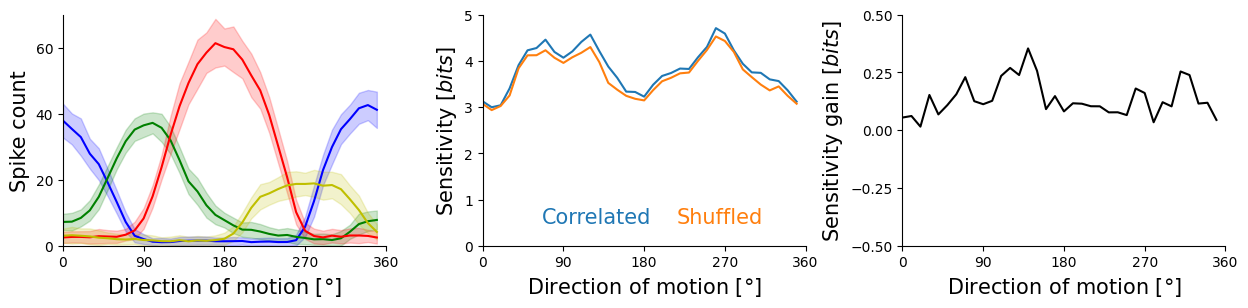

In [587]:
## ========== RANDOM QUAD =================
# np.random.seed(2)
rndm_quad = np.random.choice(648)

## ========== FRANKE QUAD =================
felix_cells = [1,5,8,15]
rndm_quad = np.where(np.all(np.sort(np.copy(data_dict['original_cell_idx_quads']).astype(int), axis=1)\
                      ==np.sort(felix_cells), axis=1))[0][0]
colors = ['r', 'g', 'b', 'y']

stim = np.arange(0,360,10)

print(rndm_quad)

plt.rcParams['axes.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15

ex_quad = raw_dict['spikeCounts'][:,:,data_dict['original_cell_idx_quads'][rndm_quad].astype(int)]
ex_tcs = raw_dict['spikeCounts'][:,:,data_dict['original_cell_idx_quads'][rndm_quad].astype(int)].mean(axis=0).T
ex_tcs_sh = SHUFFLE(raw_dict['spikeCounts'][:,:,data_dict['original_cell_idx_quads'][rndm_quad].astype(int)]).mean(axis=0).T

print(ex_tcs.shape)


ex_tcs = raw_dict['spikeCounts'][:,:,data_dict['original_cell_idx_quads'][rndm_quad].astype(int)].mean(axis=0).T

exact_ssi = ssiMod.MC_SSI(ex_tcs)

from matplotlib import gridspec
gs = gridspec.GridSpec(1,3, wspace = 0.3)
fig = plt.figure(figsize = (15,3))
ax = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1])
ax2 = fig.add_subplot(gs[2])

colors = ['b', 'g', 'r', 'y']
for cell in range(ex_quad.shape[2]):
    ax.plot(stim, ex_quad[:,:,cell].mean(axis=0), color = colors[cell])
    ax.fill_between(stim, ex_quad[:,:,cell].mean(axis=0)-ex_quad[:,:,cell].std(axis=0),\
                          ex_quad[:,:,cell].mean(axis=0)+ex_quad[:,:,cell].std(axis=0),\
                    color = colors[cell], alpha = 0.2)
ax.set_xticks(np.arange(0,361,90))
ax.set_xlim(0,360)
ax.set_yticks(np.arange(0,81,20))
ax.set_ylim(0,70)
ax.set_xlabel(r'Direction of motion [$\degree$]')
ax.set_ylabel('Spike count')
ax.text(-0.15, 1.1, 'A)', fontweight='bold')


ax1.plot(stim, corr_ssis[rndm_quad], label = 'Correlated', color = 'tab:blue')
ax1.plot(stim, uncorr_ssis[rndm_quad], label = 'Shuffled', color = 'tab:orange')
# ax1.plot(stim, exact_ssi, label = 'Cond. Indep.\nPoisson Model', color = 'tab:green')

# ax1.axvline(stim[corr_ssis[rndm_quad].argmin()], ls = '--', c='grey', lw = 2)

leg1 = ax1.legend(handlelength = 0, labelcolor = 'linecolor', ncol = 2, loc = 'lower center',\
         columnspacing = 0.4, frameon=0)
# leg1.set_zorder(5)
# leg1.get_frame().set_edgecolor(None)
# leg1.get_frame().set_alpha(1)

leg1.get_frame().set_linewidth(0)
ax1.set_ylim(0,5)
ax1.set_xlim(0,360)
ax1.set_xticks(np.arange(0,361,90))
ax1.set_ylabel('Sensitivity [$bits$]')
ax1.set_xlabel(r'Direction of motion [$\degree$]')
ax1.text(-0.15, 1.1, 'B)', fontweight='bold')



ax2.plot(stim, corr_ssis[rndm_quad]-uncorr_ssis[rndm_quad], c='k')
# ax2.axvline(stim[corr_ssis[rndm_quad].argmin()], ls = '--', c='grey', lw = 2)
ax2.set_xticks(np.arange(0,361,90))
ax2.set_yticks(np.arange(-0.5, 0.51, 0.25))
ax2.set_ylim(-0.5,0.5)
ax2.set_xlim(0,360)
ax2.set_ylabel('Sensitivity gain [$bits$]')
ax2.set_xlabel(r'Direction of motion [$\degree$]')
ax.text(-0.15, 1.1, 'C)', fontweight='bold')


fig.savefig('Corr_v_Uncorr_SSI.jpg', bbox_inches = 'tight', dpi=300)

(0.0, 120.0)

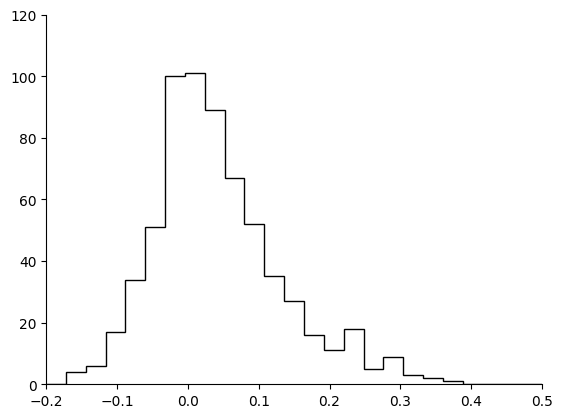

In [559]:
plt.hist(np.array([(corr_ssis-uncorr_ssis)[i,el] for i,el in enumerate(corr_ssis.argmin(axis=1))]), \
         bins = 25, range = (-0.2, 0.5), histtype = 'step', color = 'k')
plt.xlim(-0.2, 0.5)
plt.ylim(0,120)

In [449]:
mse_ssi = np.mean((corr_ssis-uncorr_ssis)**2, axis=1)

print(np.argmax(mse_ssi))
print(np.argmin(mse_ssi))

293
552
